# Final project — Structural Reliability

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY, PURPLE = "#2a6fb0", "#d9622b", "#8a8a8a", "#6a4fc0"

def clean(ax):
    # Schematic look: no tick numbers, only axis labels
    ax.set_xticks([]); ax.set_yticks([])

def mu_S(T):
    # Illustrative healthy curve: gentle slope above 0 °C, steep below
    T = np.asarray(T, dtype=float)
    return 4.0 - 0.005 * T - 0.06 * np.minimum(T, 0)

## 1. The problem

### 1.1 Detecting damage before it crosses the threshold

A monitored bridge measures its natural frequency at regular intervals. Even when the bridge is healthy, the identified frequency is not always the same. It can vary for different reasons:
- Inaccuracy of the modal identification
- Changes in traffic

If only those two sources are considered, the measurements of the healthy bridge scatter around a mean value with a standard deviation $\sigma$.

The traditional way to detect damage is to set a **threshold**, for example $\mu\pm3\sigma$, and raise an alarm when a measurement falls outside it.

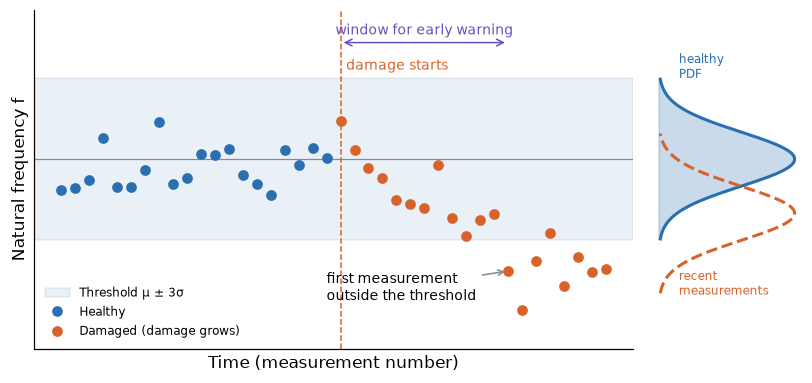

In [11]:
rng = np.random.default_rng(40)
n, onset = 40, 20
k = np.arange(n)
mu0, sigma = 4.0, 0.01
drift = np.where(k < onset, 0.0, -0.0025 * (k - onset))     # damage grows gradually
f_obs = mu0 + drift + rng.normal(0, sigma, n)                # ID error + traffic only
first_out = int(np.argmax((k >= onset) & (f_obs < mu0 - 3 * sigma)))

fig = plt.figure(figsize=(9, 4))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.05)
ax = fig.add_subplot(gs[0]); axp = fig.add_subplot(gs[1], sharey=ax)

ax.axhspan(mu0 - 3 * sigma, mu0 + 3 * sigma, color=BLUE, alpha=0.10, label="Threshold μ ± 3σ")
ax.axhline(mu0, color=GRAY, lw=0.8)
ax.plot(k[k < onset], f_obs[k < onset], "o", color=BLUE, label="Healthy")
ax.plot(k[k >= onset], f_obs[k >= onset], "o", color=ORANGE, label="Damaged (damage grows)")
ax.axvline(onset, color=ORANGE, ls="--", lw=1)
ax.text(onset + 0.4, mu0 + 0.033, "damage starts", color=ORANGE, fontsize=9)
ax.annotate("first measurement\noutside the threshold", xy=(first_out, f_obs[first_out]),
            xytext=(first_out - 13, mu0 - 0.052), arrowprops=dict(arrowstyle="->", color=GRAY), fontsize=9)
ax.annotate("", xy=(first_out, mu0 + 0.043), xytext=(onset, mu0 + 0.043),
            arrowprops=dict(arrowstyle="<->", color=PURPLE))
ax.text((onset + first_out) / 2, mu0 + 0.046, "window for early warning", color=PURPLE, ha="center", fontsize=9)
ax.set_xlabel("Time (measurement number)"); ax.set_ylabel("Natural frequency f")
ax.set_ylim(mu0 - 0.07, mu0 + 0.055); clean(ax); ax.legend(frameon=False, fontsize=8, loc="lower left")

ff = np.linspace(mu0 - 0.07, mu0 + 0.055, 300)
pdf_h = stats.norm.pdf(ff, mu0, sigma)
pdf_r = stats.norm.pdf(ff, mu0 - 0.02, sigma)
mh, mr = pdf_h > 0.5, pdf_r > 0.5
axp.plot(pdf_h[mh], ff[mh], color=BLUE, lw=2); axp.fill_betweenx(ff[mh], 0, pdf_h[mh], color=BLUE, alpha=0.25)
axp.plot(pdf_r[mr], ff[mr], color=ORANGE, lw=2, ls="--")
axp.text(pdf_h.max() * 0.15, mu0 + 0.03, "healthy\nPDF", color=BLUE, fontsize=8)
axp.text(pdf_r.max() * 0.15, mu0 - 0.05, "recent\nmeasurements", color=ORANGE, fontsize=8)
axp.axis("off")
plt.show()

While the damage is small, the measurements stay inside the threshold, so the $3\sigma$ rule does not raise an alarm.

However, the measurements no longer behave like those of the healthy bridge: they gradually shift downward.

If the PDF of the healthy bridge is known and is continuously compared with the incoming measurements, this **change in the distribution** can be detected and an alert issued before the damage is large enough for the frequencies to leave the threshold.

### 1.2 The additional problem: temperature

In reality, the frequency also changes with temperature. In cities like Edmonton, with very harsh winters, temperature changes can push the measured frequencies outside the threshold and trigger false alarms, or the effect of the cold can mask real damage.

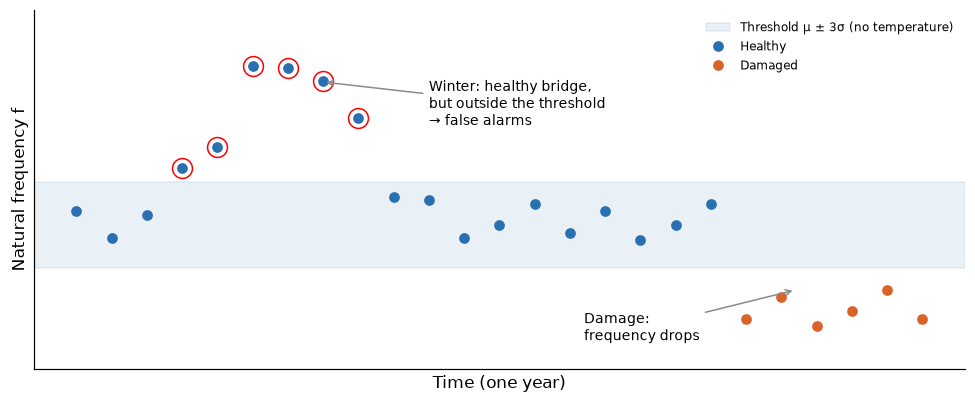

In [12]:
t = np.linspace(0, 12, 25)                                  # months
f = 4.0 + 0.12 * np.exp(-((t - 3) / 1.2) ** 2)              # winter rise
f = f - np.where(t > 9, 0.06, 0.0)                         # damage drop
f = f + np.array([0.01, -0.01, 0.0, 0.015, -0.005] * 5)    # small scatter
band = 0.03                                                 # same 3-sigma threshold as before

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhspan(4.0 - band, 4.0 + band, color=BLUE, alpha=0.10, label="Threshold μ ± 3σ (no temperature)")
ax.plot(t[t <= 9], f[t <= 9], "o", color=BLUE, label="Healthy")
ax.plot(t[t > 9], f[t > 9], "o", color=ORANGE, label="Damaged")
winter = (t <= 9) & (f > 4.0 + band)
ax.plot(t[winter], f[winter], "o", ms=13, mfc="none", mec="red")
ax.annotate("Winter: healthy bridge,\nbut outside the threshold\n→ false alarms", xy=(3.5, 4.1), xytext=(5.0, 4.07),
            arrowprops=dict(arrowstyle="->", color=GRAY), fontsize=9)
ax.annotate("Damage:\nfrequency drops", xy=(10.2, 3.955), xytext=(7.2, 3.92),
            arrowprops=dict(arrowstyle="->", color=GRAY), fontsize=9)
ax.set_ylim(3.9, 4.15)
ax.set_xlabel("Time (one year)"); ax.set_ylabel("Natural frequency f")
clean(ax); ax.legend(frameon=False, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

Therefore, the **PDF conditioned on temperature** is needed, that is, a different distribution for each temperature, so that each measurement is compared with what is expected from the healthy bridge at that same temperature.

So the question is:

> **What is the probability that this measurement, this alarm or this trend is due to real damage and not to an effect of temperature or noise?**

## 2. The data

The plan is to use the measurement data of the Z24 bridge in Switzerland. On this bridge, measurements were taken every hour for almost a year in the healthy state, followed by 15 damage scenarios applied on purpose.

The bridge was a three-span post-tensioned concrete bridge (14 + 30 + 14 m).

## 3. Special considerations

### 3.1 The effect of temperature on the healthy bridge

The frequency of the healthy bridge changes with temperature, and that change is not the same over the whole range. On the Z24 itself, Peeters and De Roeck (2001) observed that the relationship between frequency and temperature is described by **two straight lines with a break near 0 °C**: below freezing, the asphalt stiffens and the frequency rises much faster. Pivetta et al. (2026) confirmed this **bilinear** behavior in 30 prestressed concrete bridges.

Therefore, the model of the healthy bridge must account for this effect. The exact form of the relationship and the location of the break will be fitted with the data.

- Peeters, B. y De Roeck, G. (2001). *Earthquake Engineering and Structural Dynamics*, 30(2), 149–171. https://doi.org/10.1002/1096-9845(200102)30:2%3C149::AID-EQE1%3E3.0.CO;2-Z
- Pivetta, Pellegrino y Zanini (2026). *Engineering Structures*, 360, 122664. https://doi.org/10.1016/j.engstruct.2026.122664

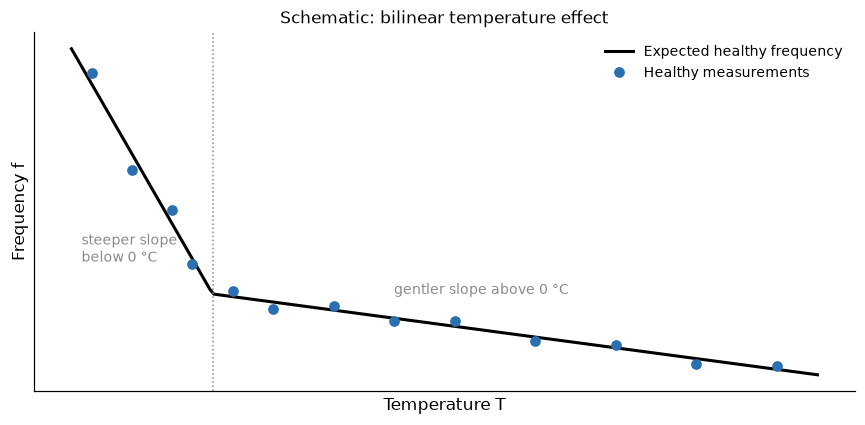

In [13]:
T_h = np.array([-6, -4, -2, -1, 1, 3, 6, 9, 12, 16, 20, 24, 28])
f_h = mu_S(T_h) + np.array([0.02, -0.03, 0.025, -0.01, 0.01, -0.012, 0.008, -0.006, 0.01, -0.008, 0.006, -0.01, 0.007])
T_line = np.linspace(-7, 30, 200)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(T_line, mu_S(T_line), color="k", lw=2, label="Expected healthy frequency")
ax.plot(T_h, f_h, "o", color=BLUE, label="Healthy measurements")
ax.axvline(0, color=GRAY, ls=":", lw=1)
ax.text(-6.5, 4.06, "steeper slope\nbelow 0 °C", fontsize=9, color=GRAY)
ax.text(9, 4.0, "gentler slope above 0 °C", fontsize=9, color=GRAY)
ax.set_xlabel("Temperature T"); ax.set_ylabel("Frequency f")
ax.set_title("Schematic: bilinear temperature effect", fontsize=11)
clean(ax); ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

### 3.2 The PDF of the healthy bridge at each temperature

Even after removing the temperature effect, the measurements of the healthy bridge do not fall exactly on the curve: traffic, wind and the error in identifying the frequency scatter them. Therefore, at each temperature, the frequency of the healthy bridge is described by a PDF, $f_S(f\mid T)$, centered on the expected frequency at that temperature.

Questions to answer with the data:

- Does the PDF follow a normal distribution or does it correspond to another type of distribution?
- Does the temperature effect change the shape of the distribution or only shift it?

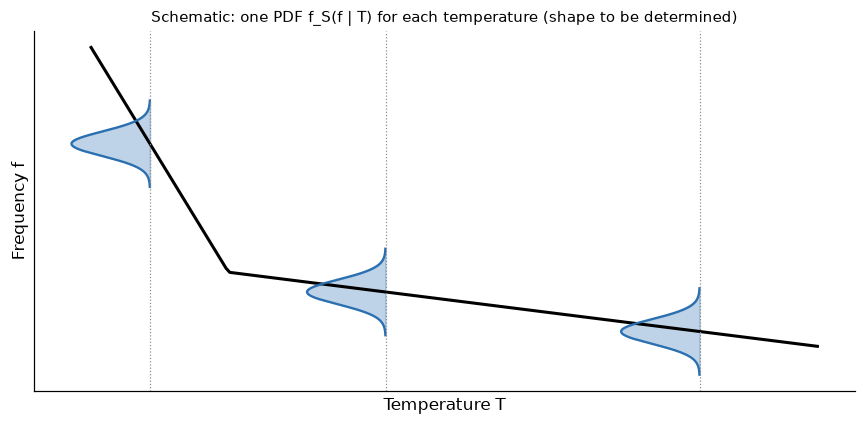

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(T_line, mu_S(T_line), color="k", lw=2)
width = 0.025
for T0 in [-4, 8, 24]:
    ff = np.linspace(mu_S(T0) - 3.5 * width, mu_S(T0) + 3.5 * width, 200)
    pdf = stats.norm.pdf(ff, mu_S(T0), width)
    ax.fill_betweenx(ff, T0, T0 - 4 * pdf / pdf.max(), color=BLUE, alpha=0.3)
    ax.plot(T0 - 4 * pdf / pdf.max(), ff, color=BLUE)
    ax.axvline(T0, color=GRAY, lw=0.8, ls=":")
ax.set_xlabel("Temperature T"); ax.set_ylabel("Frequency f")
ax.set_title("Schematic: one PDF f_S(f | T) for each temperature (shape to be determined)", fontsize=10)
clean(ax); plt.tight_layout(); plt.show()

### 3.3 The PDF of the damaged bridge

Damage reduces the stiffness and therefore lowers the frequency relative to that of the healthy bridge at the same temperature. The damaged bridge must be described with its own PDF, $f_D(f\mid T)$.

- How much does the frequency drop ($\Delta$) for each type and size of damage?
- Does the damage only shift the PDF or does it also change its shape?

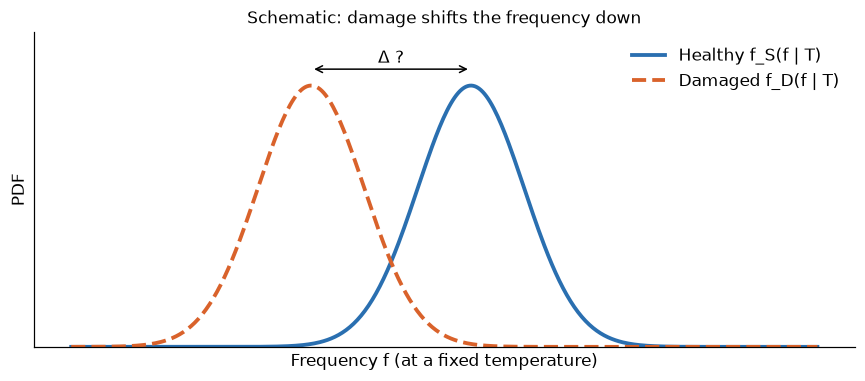

In [15]:
ff = np.linspace(3.80, 4.08, 400)
pdf_S = stats.norm.pdf(ff, 3.95, 0.02)
pdf_D = stats.norm.pdf(ff, 3.89, 0.02)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ff, pdf_S, color=BLUE, lw=2.5, label="Healthy f_S(f | T)")
ax.plot(ff, pdf_D, color=ORANGE, lw=2.5, ls="--", label="Damaged f_D(f | T)")
ax.annotate("", xy=(3.89, 21.2), xytext=(3.95, 21.2), arrowprops=dict(arrowstyle="<->"))
ax.text(3.92, 21.7, "Δ ?", ha="center"); ax.set_ylim(0, 24)
ax.set_xlabel("Frequency f (at a fixed temperature)"); ax.set_ylabel("PDF")
ax.set_title("Schematic: damage shifts the frequency down", fontsize=11)
clean(ax); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 4. Questions I will try to answer

1. If a measurement crosses the threshold, what is the probability that it is real damage?

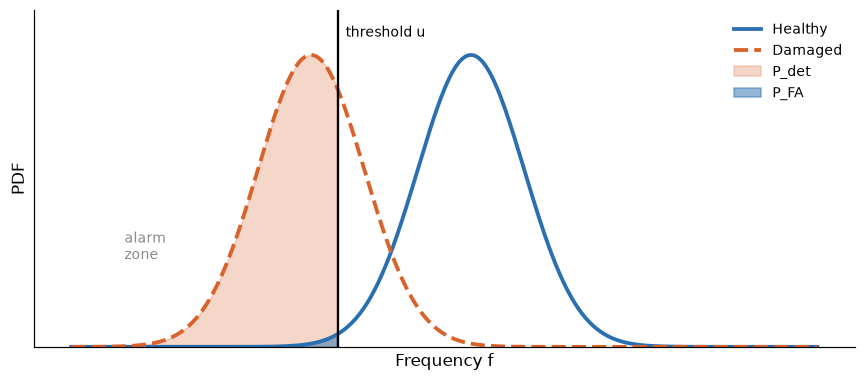

In [16]:
u = 3.90
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ff, pdf_S, color=BLUE, lw=2.5, label="Healthy")
ax.plot(ff, pdf_D, color=ORANGE, lw=2.5, ls="--", label="Damaged")
ax.fill_between(ff[ff <= u], pdf_D[ff <= u], color=ORANGE, alpha=0.25, label="P_det")
ax.fill_between(ff[ff <= u], pdf_S[ff <= u], color=BLUE, alpha=0.5, label="P_FA")
ax.axvline(u, color="k", lw=1.5); ax.text(u + 0.003, 21.2, "threshold u", ha="left", fontsize=9); ax.set_ylim(0, 23)
ax.text(3.82, 6, "alarm\nzone", fontsize=9, color=GRAY)
ax.set_xlabel("Frequency f"); ax.set_ylabel("PDF")
clean(ax); ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

2. Given a specific measurement at its temperature, what is the probability that the bridge is damaged?

The probability that the bridge is damaged or not could be determined for any measurement at a given temperature, without the measurement having to cross the threshold set for the healthy bridge.

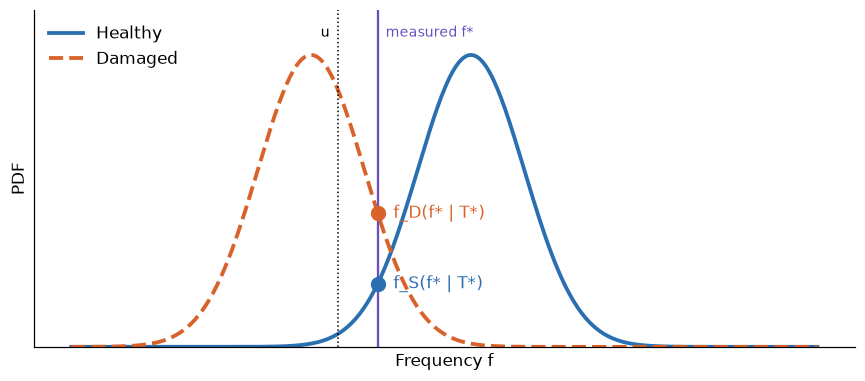

In [17]:
f_star = 3.915
hS = stats.norm.pdf(f_star, 3.95, 0.02)
hD = stats.norm.pdf(f_star, 3.89, 0.02)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ff, pdf_S, color=BLUE, lw=2.5, label="Healthy")
ax.plot(ff, pdf_D, color=ORANGE, lw=2.5, ls="--", label="Damaged")
ax.axvline(f_star, color=PURPLE, lw=1.5)
ax.plot([f_star], [hS], "o", color=BLUE, ms=9); ax.plot([f_star], [hD], "o", color=ORANGE, ms=9)
ax.text(f_star + 0.004, hS, " f_S(f* | T*)", color=BLUE, va="center")
ax.text(f_star + 0.004, hD, " f_D(f* | T*)", color=ORANGE, va="center")
ax.axvline(u, color="k", lw=1, ls=":"); ax.text(u - 0.003, 21.2, "u", ha="right", fontsize=9)
ax.text(f_star + 0.003, 21.2, "measured f*", color=PURPLE, fontsize=9)
ax.set_xlabel("Frequency f"); ax.set_ylabel("PDF")
clean(ax); ax.legend(frameon=False, loc="upper left"); ax.set_ylim(0, 23); plt.tight_layout(); plt.show()

3. If the damage progresses gradually, can it be detected before the frequency crosses the threshold? (Continuous monitoring)

The measurements drop but almost never cross the threshold; the idea is to see whether the Bayesian probability, by accumulating that evidence, reacts earlier.

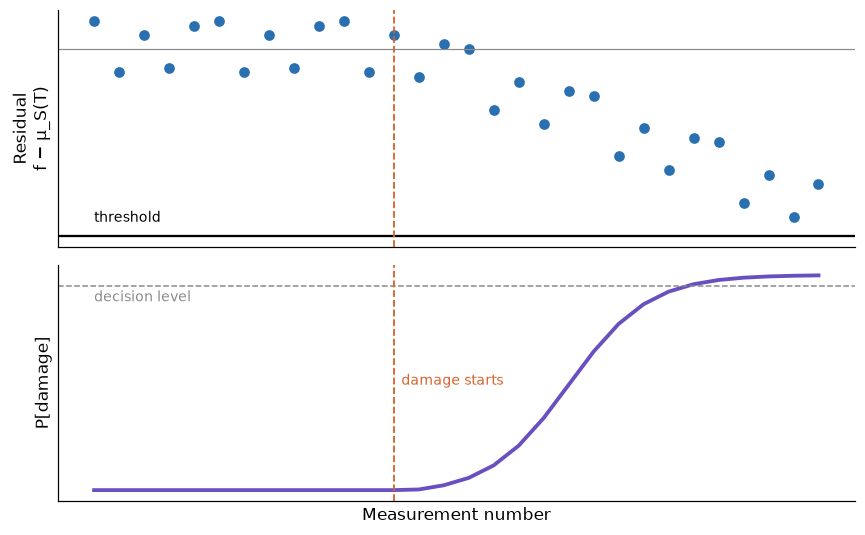

In [ ]:
k = np.arange(30)
onset = 12
resid = np.where(k < onset, 0.0, -0.004 * (k - onset)) + np.array([0.012, -0.01, 0.006, -0.008, 0.01] * 6)
alarm_level = -0.08
p = np.where(k < onset, 0.02, 1 / (1 + np.exp(-(k - onset - 7) / 1.6)))
p = np.maximum(p, 0.02)

fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(k, resid, "o", color=BLUE)
ax[0].axhline(0, color=GRAY, lw=0.8)
ax[0].axhline(alarm_level, color="k", lw=1.5); ax[0].text(0, alarm_level + 0.006, "threshold", fontsize=9)
ax[0].set_ylabel("Residual\nf − μ_S(T)")
ax[1].plot(k, p, color=PURPLE, lw=2.5)
ax[1].axhline(0.95, color=GRAY, ls="--", lw=1); ax[1].text(0, 0.88, "decision level", fontsize=9, color=GRAY)
ax[1].set_ylabel("P[damage]"); ax[1].set_xlabel("Measurement number")
for a in ax:
    a.axvline(onset, color=ORANGE, ls="--", lw=1.2); clean(a)
ax[1].text(onset + 0.3, 0.5, "damage starts", color=ORANGE, fontsize=9)
plt.tight_layout(); plt.show()